In [23]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [24]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [25]:
# 3. Lectura de la ruta
base_dir = r"Cars_Body_Type/train"

## Fuente del dataset

Para este ejercicio se utiliza el dataset **Cars Body Type Cropped**, publicado en Kaggle por **ademboukhris**.

[Consultar el dataset en Kaggle](https://www.kaggle.com/datasets/ademboukhris/cars-body-type-cropped?resource=download-directory)

En este notebook se cargaron **5350 imágenes** distribuidas en **7 clases**, correspondientes a diferentes tipos de carrocería:

- Convertible
- Coupe
- Hatchback
- Pick-Up
- SUV
- Sedan
- VAN

In [26]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 5350 imagenes, 150x 150 pixeles, y 3 canales (RGB) por ser imagenes a color

Shape: (5350, 150, 150, 3)
Ejemplo etiquetas: ['Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible'
 'Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible']


In [27]:
# Conteo de imágenes cargadas por clase
clases, conteos = np.unique(Y, return_counts=True)
for clase, conteo in zip(clases, conteos):
    print(f"{clase}: {conteo} imágenes")

print("Cumple mínimo de 200 por clase:", bool(np.all(conteos >= 200)))

Convertible: 811 imágenes
Coupe: 721 imágenes
Hatchback: 701 imágenes
Pick-Up: 759 imágenes
SUV: 847 imágenes
Sedan: 729 imágenes
VAN: 782 imágenes
Cumple mínimo de 200 por clase: True


In [28]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['Convertible' 'Coupe' 'Hatchback' 'Pick-Up' 'SUV' 'Sedan' 'VAN']


In [29]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

## Preparación de las imágenes

Para entrenar el modelo, se prepararon las imágenes mediante los siguientes pasos:

- **Carga y asignación de etiquetas:** se recorren las subcarpetas de `train` y se utiliza el nombre de cada carpeta como etiqueta. Esto permite relacionar cada imagen con su tipo de carrocería sin etiquetarla manualmente.

- **Redimensionado a 150 × 150 píxeles:** todas las imágenes se llevan al mismo tamaño para que tengan dimensiones compatibles con la entrada de la red. Este tamaño busca un equilibrio entre el detalle visual y el costo de procesamiento.

- **Normalización:** se dividen los valores de los píxeles entre 255 para pasarlos del rango de 0 a 255 al rango de 0 a 1. Esto mantiene una escala de entrada uniforme y puede facilitar la optimización durante el entrenamiento.

- **Codificación de etiquetas:** se utiliza `LabelEncoder` para convertir los nombres de las clases en etiquetas numéricas que puedan utilizarse al entrenar el modelo.

- **Separación de datos:** se reserva el 80 % de las imágenes para entrenamiento y el 20 % para evaluación. Se utiliza una división estratificada para mantener aproximadamente la proporción de cada clase en ambos conjuntos.

## MODELO BASE

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom
import tensorflow as tf

tf.random.set_seed(3)
np.random.seed(3)

modelo = Sequential()

# Primera capa convolucional para extraer características básicas.
modelo.add(Conv2D(16, (3,3), activation='relu', input_shape=(150,150,3)))
modelo.add(MaxPooling2D(2,2))

# Segunda capa convolucional para identificar características más complejas.
modelo.add(Conv2D(32, (3,3), activation='relu'))
modelo.add(MaxPooling2D(2,2))

# Tercera capa convolucional para profundizar en la extracción de características.
modelo.add(Conv2D(64, (3,3), activation='relu'))
modelo.add(MaxPooling2D(2,2))

# Convierte los mapas de características en un vector.
modelo.add(Flatten())

# Desactiva aleatoriamente algunas conexiones durante el entrenamiento.
modelo.add(Dropout(0.2))

# Capa densa para realizar la clasificación.
modelo.add(Dense(32, activation='relu'))

# Clasificación en las siete categorías.
modelo.add(Dense(7, activation='softmax'))

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=8
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.2895 - loss: 1.7617
Epoch 2/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.4215 - loss: 1.4910
Epoch 3/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.5019 - loss: 1.3027
Epoch 4/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5512 - loss: 1.1808
Epoch 5/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5984 - loss: 1.0805
Epoch 6/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6175 - loss: 1.0038
Epoch 7/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6488 - loss: 0.9292
Epoch 8/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.6703 - loss: 0.8744
Epoch 9/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6785 - loss: 0.8324
Epoch 10/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.6960 - loss: 0.8138
Epoch 11/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7114 - loss: 0.7413
Epoch 12/20
535/535 ━━━━━━━━━━━━━━━━━━━━

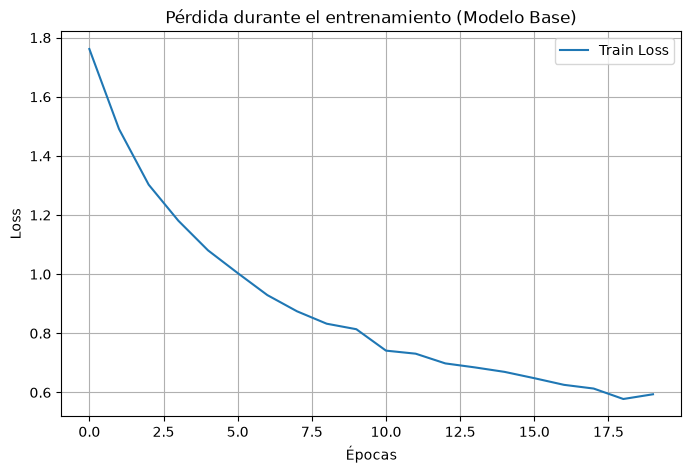

In [31]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

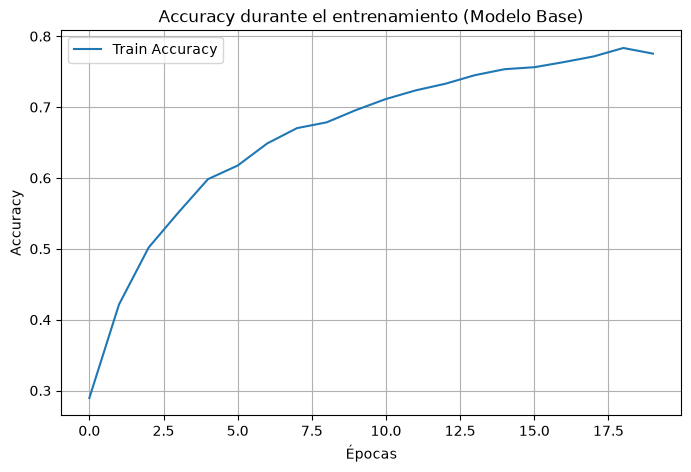

In [32]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [33]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
===== TRAIN =====
Accuracy: 0.8343457943925233
F1-score: 0.8327456598309344

===== TEST =====
Accuracy: 0.7411214953271028
F1-score: 0.7415840493091903


## Interpretación de los resultados del modelo base

Después de entrenar durante 20 épocas, se obtuvieron los siguientes resultados en la evaluación:

| Conjunto | Accuracy | F1-score ponderado |
| --- | ---: | ---: |
| Entrenamiento | 0.82477 | 0.82180 |
| Prueba | 0.73551 | 0.73192 |

### Conclusión

El modelo clasifica correctamente aproximadamente el 73.55 % de las imágenes del conjunto de prueba. Este resultado sirve como referencia para comparar el modelo base con la versión optimizada.

## MODELO CNN OPTIMIZADO

In [34]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    shear_range=0.2, #las imágenes pueden ser deformadas hasta un 20%
    zoom_range=0.2, #las imágenes pueden aumentarse hasta un 20% en su tamaño original.
    horizontal_flip=True, #voltear horizontalmente las imágenes de manera aleatoria durante el entrenamiento
    rotation_range=20, #rotacion de las imágenes (20 grados)
    fill_mode='nearest' # Rellena los píxeles fuera de los límites de la imagen con los valores más cercanos
)

In [ ]:
# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers

modelo_opt = Sequential() # Se crea un nuevo modelo secuencial para el modelo optimizado, que permitirá construir una arquitectura más compleja añadiendo capas de manera secuencial.

# Capas convolucionales con normalización por lotes y activación ReLU para mejorar la capacidad de extracción de características, seguidas de capas de pooling para reducir la dimensionalidad.
modelo_opt.add(Conv2D(16, (3,3), input_shape=(150,150,3))) 
modelo_opt.add(layers.BatchNormalization()) # La normalización por lotes ayuda a estabilizar y acelerar el entrenamiento al normalizar las activaciones de la capa anterior, lo que puede mejorar la convergencia del modelo.
modelo_opt.add(layers.Activation('relu')) # La función de activación ReLU introduce no linealidad en el modelo, lo que permite aprender relaciones más complejas entre las características extraídas por la capa convolucional.
modelo_opt.add(MaxPooling2D(2,2)) # Agrega una capa de pooling que reduce la dimensionalidad de las características extraídas por la capa convolucional, utilizando un tamaño de ventana de 2x2.

modelo_opt.add(Conv2D(32, (3,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

modelo_opt.add(Conv2D(64, (3, 3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2, 2))

modelo_opt.add(Conv2D(128, (3, 3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2, 2))

modelo_opt.add(Conv2D(256, (3, 3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2, 2))

# capa flatten para convertir las características extraídas en un vector unidimensional, seguido de capas densas con dropout para prevenir el sobreajuste y mejorar la capacidad de generalización del modelo.
modelo_opt.add(Flatten())

# Capas densas para la clasificación final, con dropout para prevenir el sobreajuste.
modelo_opt.add(Dense(128, activation='relu'))
modelo_opt.add(Dropout(0.3))

modelo_opt.add(Dense(64, activation='relu'))
modelo_opt.add(Dropout(0.3))

modelo_opt.add(Dense(32, activation='relu'))
modelo_opt.add(Dropout(0.3))

modelo_opt.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [62]:
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=16),
    epochs=200
)

Epoch 1/200


I0000 00:00:1793489010.884055   63088 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1213387__.94


 36/268 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.1389 - loss: 2.1564

I0000 00:00:1793489020.298450   63088 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1213387__.94


268/268 ━━━━━━━━━━━━━━━━━━━━ 33s 79ms/step - accuracy: 0.1514 - loss: 1.9965
Epoch 2/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - accuracy: 0.1804 - loss: 1.9399
Epoch 3/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - accuracy: 0.2044 - loss: 1.8816
Epoch 4/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - accuracy: 0.2388 - loss: 1.8401
Epoch 5/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.2685 - loss: 1.7683
Epoch 6/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.2911 - loss: 1.7199
Epoch 7/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.3047 - loss: 1.6846
Epoch 8/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.3322 - loss: 1.6267
Epoch 9/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.3463 - loss: 1.5779
Epoch 10/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - accuracy: 0.3514 - loss: 1.5518
Epoch 11/200
268/268 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.3491 - loss: 1.5253
Epoch 12/200
268/268 ━━━━━━━━━━

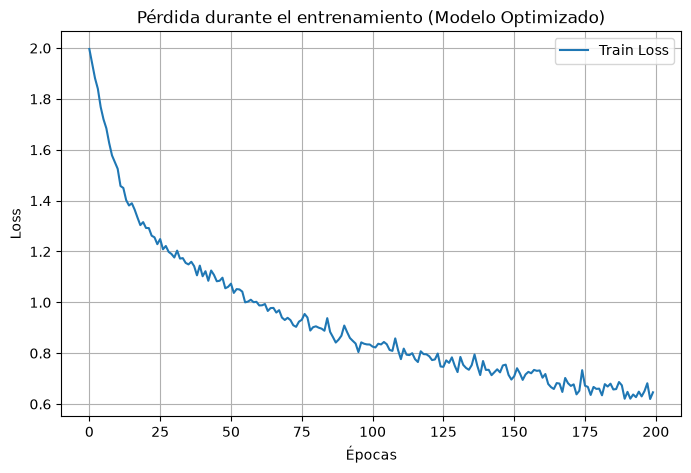

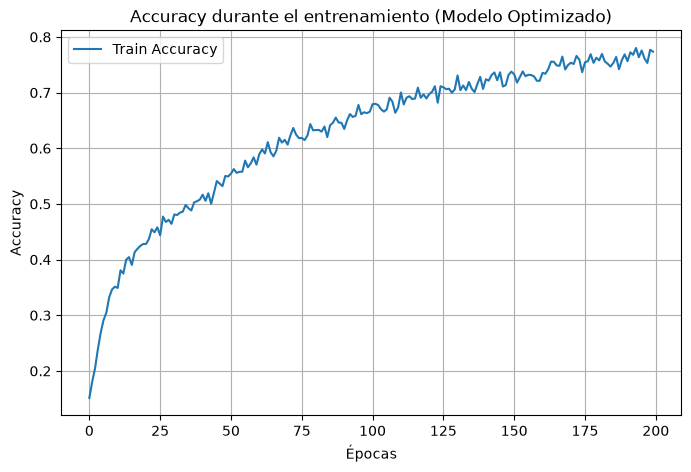

In [63]:
import matplotlib.pyplot as plt

# =========================
# LOSS
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [64]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

134/134 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step
===== TRAIN =====
Accuracy: 0.8399532710280374
F1-score: 0.8398978272986044

===== TEST =====
Accuracy: 0.6962616822429907
F1-score: 0.6990369067664304


aqui sacar conclusiones

In [39]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_cars.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

# Despliegue

In [40]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1. Cargar modelo y label encoder
print("Cargando modelo y label encoder...")
modelo = load_model("modelo_cars.keras")

with open("labelencoder.pkl", "rb") as f:
    labelencoder = pickle.load(f)

# 2. Definir ruta de prueba
ruta_nuevos = r"Cars_Body_Type/test"
img_size = (150, 150)

# 3. Función actualizada para buscar imágenes dentro de subcarpetas
def predecir_y_mostrar_carpetas(ruta_raiz, modelo, labelencoder, img_size=img_size):
    resultados = []
    
    if not os.path.exists(ruta_raiz):
        print(f"Error: La ruta '{ruta_raiz}' no existe.")
        return resultados

    # Usamos os.walk para recorrer la carpeta principal y todas sus subcarpetas
    total_imagenes = 0
    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                total_imagenes += 1

    if total_imagenes == 0:
        print(f"No se encontraron imágenes válidas en '{ruta_raiz}' ni en sus subcarpetas.")
        return resultados

    print(f"Se encontraron {total_imagenes} imágenes. Procesando...")

    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                ruta = os.path.join(root, archivo)
                # Opcional: obtener la clase real basada en el nombre de la subcarpeta
                clase_real = os.path.basename(root)

                # Cargar y preprocesar la imagen
                img = Image.open(ruta)
                img_resized = img.resize(img_size)
                
                img_array = np.array(img_resized) / 255.0
                img_array = np.expand_dims(img_array, axis=0)

                # Predicción
                pred = modelo.predict(img_array, verbose=0)
                clase_pred = np.argmax(pred, axis=1)

                # Convertir a etiqueta original
                etiqueta = labelencoder.inverse_transform(clase_pred)
                
                resultados.append((archivo, etiqueta[0]))

                # Imprimir resultado en consola (mostrando la carpeta/clase real y la predicha)
                print(f"[{clase_real}] {archivo} → Predicción: {etiqueta[0]}")

                # Mostrar imagen con matplotlib
                plt.figure(figsize=(4, 4))
                plt.imshow(img)
                plt.title(f"Real: {clase_real} | Pred: {etiqueta[0]}")
                plt.axis("off")
                plt.show()

    return resultados

# Ejecutar el proceso actualizado
resultados = predecir_y_mostrar_carpetas(ruta_nuevos, modelo, labelencoder)

Cargando modelo y label encoder...
Se encontraron 802 imágenes. Procesando...


KeyboardInterrupt: 